In [11]:
import joblib
defaults = X_train.median().to_dict()
joblib.dump(defaults, "../model/noshow_defaults.joblib")
print(len(defaults), "defaults saved")
print(list(X_train.columns))

61 defaults saved
['appointment_time', 'age', 'under_12_years_old', 'over_60_years_old', 'patient_needs_companion', 'average_temp_day', 'average_rain_day', 'max_temp_day', 'max_rain_day', 'rainy_day_before', 'storm_day_before', 'Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'Scholarship', 'SMS_received', 'age_missing', 'day_of_week', 'month', 'week_of_year', 'day_of_month', 'is_weekend', 'young_adult', 'specialty_unknown', 'disability_unknown', 'missing_count', 'specialty_assist', 'specialty_enf', 'specialty_occupational therapy', 'specialty_pedagogo', 'specialty_physiotherapy', 'specialty_psychotherapy', 'specialty_sem especialidade', 'specialty_speech therapy', 'gender_I', 'gender_M', 'disability_intellectual', 'disability_motor', 'appointment_shift_morning', 'rain_intensity_moderate', 'rain_intensity_no_rain', 'rain_intensity_weak', 'heat_intensity_heavy_cold', 'heat_intensity_heavy_warm', 'heat_intensity_mild', 'heat_intensity_warm', 'age_group_13-18', 'age_group_19-40', 'age

Save the model

In [10]:
import joblib, os
os.makedirs("../model", exist_ok=True)

joblib.dump(lgbm, "../model/noshow_model.joblib")
joblib.dump(list(X_train.columns), "../model/noshow_columns.joblib")

['../model/noshow_columns.joblib']

feature importance

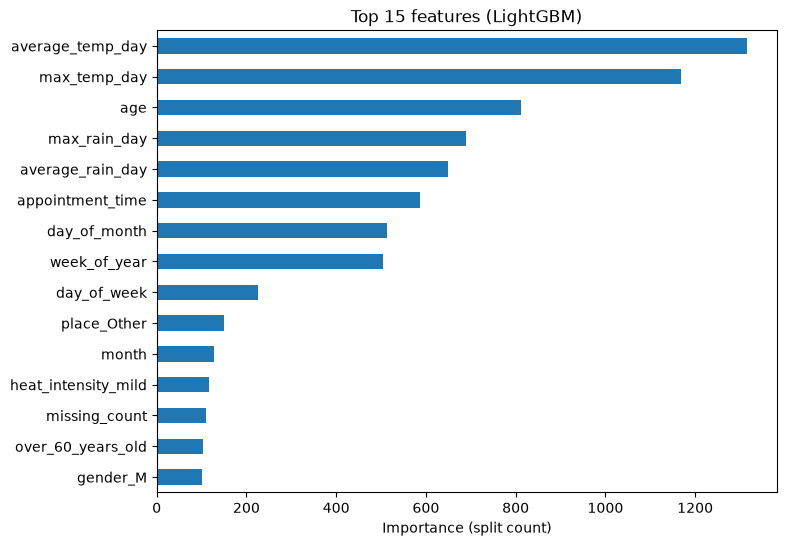

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(lgbm.feature_importances_, index=X_train.columns).sort_values(ascending=False)
imp.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 features (LightGBM)")
plt.xlabel("Importance (split count)")
plt.show()

Baseline (Logistic Regression, balanced): ROC-AUC 0.76, F1 0.62, precision 0.49, recall 0.84. Catches 84% of no-shows but about half of flagged patients attend (false alarms). Next: compare with Random Forest and LightGBM, then tune the threshold.

best F1 threshold for each model

In [8]:
import numpy as np
from sklearn.metrics import precision_recall_curve

for name, m in models.items():
    pr = m.predict_proba(X_test)[:, 1]
    prec, rec, thr = precision_recall_curve(y_test, pr)
    f1s = 2 * prec * rec / (prec + rec + 1e-9)
    i = np.argmax(f1s[:-1])
    print(f"{name}: best threshold {thr[i]:.2f} -> F1 {f1s[i]:.3f} (precision {prec[i]:.3f}, recall {rec[i]:.3f})")

Logistic Regression: best threshold 0.49 -> F1 0.622 (precision 0.491, recall 0.847)
Random Forest: best threshold 0.52 -> F1 0.632 (precision 0.508, recall 0.836)
LightGBM: best threshold 0.42 -> F1 0.636 (precision 0.507, recall 0.854)


compare all three in one table

In [7]:
models = {"Logistic Regression": logreg, "Random Forest": rf, "LightGBM": lgbm}
rows = []
for name, m in models.items():
    p = m.predict(X_test)
    pr = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "F1": round(f1_score(y_test, p), 3),
        "ROC-AUC": round(roc_auc_score(y_test, pr), 3),
        "Precision": round(precision_score(y_test, p), 3),
        "Recall": round(recall_score(y_test, p), 3),
    })
pd.DataFrame(rows)

,Model,F1,ROC-AUC,Precision,Recall
0,Logistic Regression,0.620,0.760,0.492,0.839
1,Random Forest,0.631,0.776,0.504,0.844
2,LightGBM,0.635,0.786,0.516,0.827


LightGBM

In [6]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
lgbm.fit(X_train, y_train)

,learning_rate,0.05
,n_estimators,300
,class_weight,'balanced'
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,min_split_gain,0.0


Random Forest

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=42
)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [4]:
from sklearn.metrics import f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix

pred = logreg.predict(X_test)
proba = logreg.predict_proba(X_test)[:, 1]

print("F1:       ", round(f1_score(y_test, pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, proba), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall:   ", round(recall_score(y_test, pred), 3))
print(confusion_matrix(y_test, pred))

F1:        0.62
ROC-AUC:   0.76
Precision: 0.492
Recall:    0.839
[[8929 6023]
 [1125 5842]]


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)
logreg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](61,)","['appointment_time','age','under_12_years_old',...,'place_PENHA', 'place_PORTO BELO','place_Unknown']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,61
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [2]:
X_train = X_train.astype(float)
X_test = X_test.astype(float)

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

data = pd.read_csv("../data/model_ready.csv")
X = data.drop(columns=["no_show"])
y = data["no_show"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(87674, 61) (21919, 61)
0.3178251248944955 0.3178520917925088
